# Plot Voltage from DAQ

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [34]:


# ----------------------- USER-CONFIGURABLE SETTINGS -----------------------
#CSV_PATH = "ppln_only_data\\1550_calibration\\calibration_voltage_20261031_1727.csv"  # path to the logged CSV file
CSV_PATH = "ppln_only_data\\spec_1_daq_99\\piezo_50_20261104_2214.csv"  # path to the logged CSV file --- IGNORE ---
# ----------------------------------------------------------------------------

# Load the log
df = pd.read_csv(CSV_PATH, parse_dates=["timestamp"])


Average voltage 0.38788763015547817


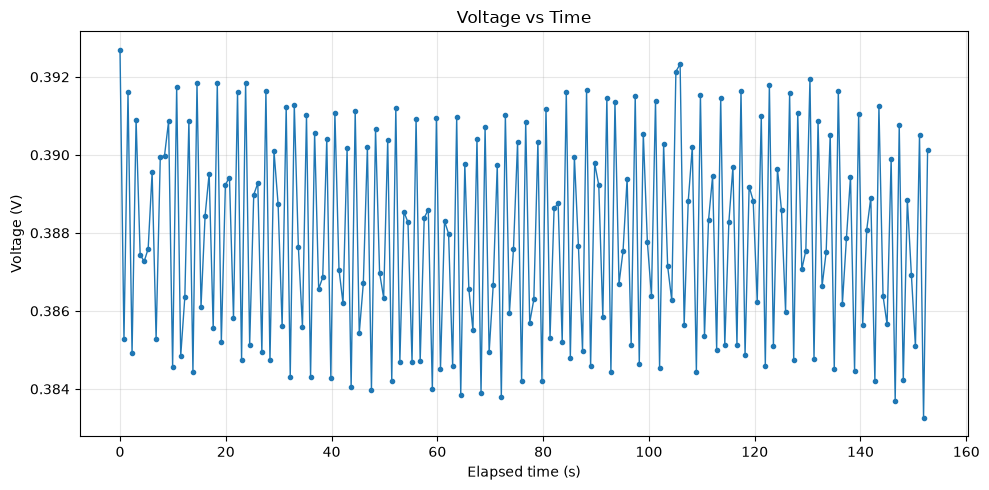

In [35]:
print(f"Average voltage {np.mean(df["measured_voltage_V"])}")


# Elapsed time (seconds) since the first sample, often easier to read than wall-clock time
df["elapsed_s"] = (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["elapsed_s"], df["measured_voltage_V"], marker="o", markersize=3, linewidth=1)
ax.set_xlabel("Elapsed time (s)")
ax.set_ylabel("Voltage (V)")
ax.set_title("Voltage vs Time")
ax.grid(True, alpha=0.3)
# ax.set_xlim(left=0)
# ax.set_ylim(bottom=0, top=6)

plt.tight_layout()
plt.show()

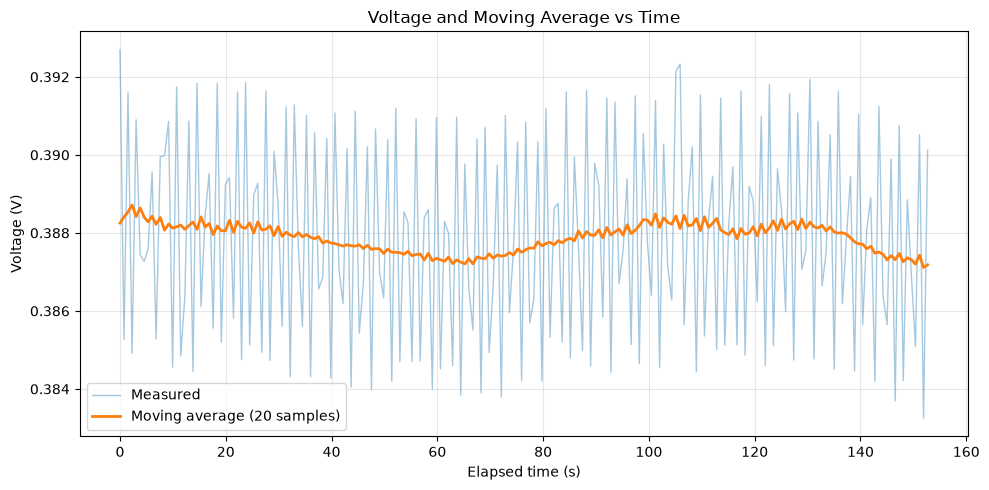

In [36]:
window = 20  # samples

df["moving_average_V"] = df["measured_voltage_V"].rolling(
    window=window, center=True, min_periods=1
).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["elapsed_s"], df["measured_voltage_V"], alpha=0.4, linewidth=1, label="Measured")
ax.plot(df["elapsed_s"], df["moving_average_V"], linewidth=2, label=f"Moving average ({window} samples)")
ax.set_xlabel("Elapsed time (s)")
ax.set_ylabel("Voltage (V)")
ax.set_title("Voltage and Moving Average vs Time")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()